In [4]:
import pandas as pd
import numpy as np

In [13]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split

data = load_wine()
X = pd.DataFrame(data.data, columns=data.feature_names) # type: ignore
y = pd.DataFrame(data.target, columns=['target']) # type: ignore

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [22]:
class my_linear:
    def __init__(self, input_size, output_size):
        self.W = np.random.randn(input_size, output_size) * 0.01
        self.b = np.zeros(output_size)

    def forward(self, x):
        self.x = x
        return np.dot(x, self.W) + self.b

    def backward(self, dL_ds, lr = 0.001):
        dL_db = np.mean(dL_ds, axis=0)
        dL_dw = np.dot(self.x.T, dL_ds)

        self.b -= dL_db * lr
        self.W -= dL_dw * lr

In [15]:
def softmax(logits):
    max_logits = np.max(logits, axis=1, keepdims=True)
    shifted_logits = logits - max_logits

    exp_logits = np.exp(shifted_logits)

    probs = exp_logits / np.sum(exp_logits, axis=1, keepdims=True)

    return probs

class SoftmaxCrossEntropy:
    def __init__(self):
        self.probs = None
        self.y_true_one_hot = None

    def forward(self, logits, y_true):
        self.probs = softmax(logits)

        N = logits.shape[0]

        y_true = y_true.ravel() 

        self.y_true_one_hot = np.zeros_like(self.probs)
        self.y_true_one_hot[np.arange(N), y_true] = 1

        loss = -np.sum(self.y_true_one_hot * np.log(self.probs + 1e-15)) / N

        return loss

    def backward(self):
        N = self.probs.shape[0] # type: ignore
        return (self.probs - self.y_true_one_hot) / N # type: ignore

In [32]:
linear = my_linear(13, 3)
softmax_cross_entropy = SoftmaxCrossEntropy()

lr = 0.01

history = []

for epoch in range(100):
    logits = linear.forward(X_train)
    loss = softmax_cross_entropy.forward(logits, y_train.values)
    dL_ds = softmax_cross_entropy.backward()
    linear.backward(dL_ds, lr)

    history.append(loss)

    if epoch % 10 == 0:
        print(f'Epoch: {epoch}, Loss: {loss}')

Epoch: 0, Loss: 1.1004960643735116
Epoch: 10, Loss: 0.9430440293998831
Epoch: 20, Loss: 0.821554121990757
Epoch: 30, Loss: 0.7272712756346409
Epoch: 40, Loss: 0.6531104962720959
Epoch: 50, Loss: 0.5937831420604599
Epoch: 60, Loss: 0.5454829325420933
Epoch: 70, Loss: 0.5054982011892928
Epoch: 80, Loss: 0.47188875532247915
Epoch: 90, Loss: 0.44325010520845803


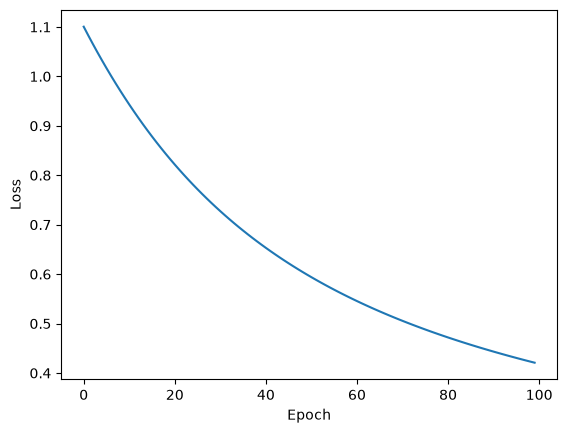

In [34]:
from matplotlib import pyplot as plt

plt.plot(history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [39]:
test_probs = linear.forward(X_test)
test_y = softmax(test_probs)
test_loss = softmax_cross_entropy.forward(test_probs, y_test.values)

print(f'Test loss: {test_loss}')
print(f'{test_y[2]}, {y_test.values[2]}')

Test loss: 0.388681192471641
[0.1022363  0.20535414 0.69240955], [2]
